# Find VitD Supplementation in Abx Cohort

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()
from regression_functions import *


import re
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [2]:
medication_assessments = adi.get_snapshot('assessments_medications')
abx_covariates = pd.read_csv("data/abx_recency_covariates.csv", dtype={'public_client_id':str}) 

In [3]:
abx_covariates

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,sex,age,BMI_CALC,abx_recency,eGFR,centered_eGFR,abx_recency_three,abx_recency_twelve
0,01071494,-0.216793,-0.110133,-0.088564,0.055447,0.006009,-40.0,No,No,F,49.0,30.598898,none,86.366123,-10.696581,0,0
1,01092042,-0.503311,-0.208429,-0.160230,-0.046219,0.061394,-7.0,No,No,F,54.0,19.483497,none,103.067192,6.004489,0,0
2,01568974,-0.149388,0.030381,0.617446,0.176120,0.042827,-7.0,No,No,F,46.0,35.662071,twelve,115.435836,18.373132,0,1
3,01601230,0.062362,-0.028922,-0.034839,0.086872,0.029430,-5.0,No,No,M,45.0,26.120098,none,88.199673,-8.863030,0,0
4,01684342,0.063423,-0.019438,-0.035673,-0.008457,0.001391,-5.0,No,No,M,32.0,22.668163,none,96.720816,-0.341887,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2596,01041538,0.029160,0.027134,0.102529,-0.517381,-0.033178,499.0,No,Yes,M,58.0,24.145898,twelve,99.333414,2.270710,0,1
2597,QIRL,0.066072,-0.023644,-0.040810,0.072321,0.034344,553.0,No,No,F,44.0,36.299927,none,111.687296,14.624593,0,0
2598,01232614,0.061376,-0.012418,-0.018141,0.031564,0.021440,593.0,No,No,F,48.0,23.960237,twelve,108.138174,11.075471,0,1
2599,01181682,0.058783,-0.010586,-0.012099,-0.051793,0.031362,629.0,No,Yes,M,49.0,24.676735,twelve,70.589153,-26.473551,0,1


In [4]:
meds_text = medication_assessments[[
    'public_client_id',
    'days_in_program',
    'assessment_vitals_prescriptions_text',
    'assessment_vitals_supplements_text']].copy()

In [5]:
pattern_vit = r'\bvit(?:amin)?s?\.?[^a-zA-Z0-9]{0,10}d\d*'
pattern_d = r'\bd\d*\b'

meds_text["vitamin_d_flag"] = (
    meds_text["assessment_vitals_prescriptions_text"].str.contains(pattern_vit, case=False, na=False, regex=True) |
    meds_text["assessment_vitals_supplements_text"].str.contains(pattern_vit, case=False, na=False, regex=True) |
    meds_text["assessment_vitals_prescriptions_text"].str.contains(pattern_d, case=False, na=False, regex=True) |
    meds_text["assessment_vitals_supplements_text"].str.contains(pattern_d, case=False, na=False, regex=True)
).astype(int)

meds_text = meds_text.dropna(subset='days_in_program')

In [6]:
# meds_vit_d_matches.assessment_vitals_prescriptions_text.tolist()

In [7]:
meds_text=meds_text.sort_values(by='days_in_program')
abx_covariates=abx_covariates.sort_values(by='days_in_program')

abx_covar_vitD = pd.merge_asof(
    abx_covariates,
    meds_text,
    by='public_client_id',
    on='days_in_program',
    direction='nearest'
)

In [8]:
pd.crosstab(abx_covar_vitD['abx_recency'], abx_covar_vitD['vitamin_d_flag'])

vitamin_d_flag,0,1
abx_recency,,
none,1046,597
three,222,146
twelve,374,216


In [9]:
vit_d_clients = abx_covar_vitD[['public_client_id', 'vitamin_d_flag']].copy()

In [10]:
# vit_d_clients.to_csv('data/vit_d_info_abx_clients.csv', index=False)

In [11]:
# Assess regex performance
# abx_covar_vitD[abx_covar_vitD.vitamin_d_flag == 0].assessment_vitals_supplements_text.tolist()

## Look at FGF23 levels in the Arivale cohort

Let's try looking at blood levels of FGF23 if it appears in the proteomics snapshot!

In [12]:
# proteins = adi.get_snapshot('proteomics_raw')

In [13]:
proteo_meta = adi.get_snapshot('proteomics_metadata')

In [14]:
# proteo_meta

In [15]:
proteo_meta[proteo_meta['gene_name'].str.contains("FGF23")]

,name,panel,uniprot,gene_name,gene_description,gene_id,transcript_id,protein_id
266,CVD2_Q9GZV9,CVD2,Q9GZV9,FGF23,fibroblast growth factor 23,ENSG00000118972,ENST00000237837,ENSP00000237837
545,INF_Q9GZV9,INF,Q9GZV9,FGF23,fibroblast growth factor 23,ENSG00000118972,ENST00000237837,ENSP00000237837


In [16]:
proteo_corr = adi.get_snapshot('proteomics_corrected')

In [17]:
fgf_23 = proteo_corr[['public_client_id','days_in_program','sample_id','CVD2_Q9GZV9','INF_Q9GZV9']].copy()
fgf_23 = fgf_23.dropna(subset='days_in_program')

fgf_23['days_in_program'] = fgf_23.loc[:, 'days_in_program'].astype(float)

In [18]:
fgf_23 = fgf_23.sort_values(by='days_in_program')
abx_covar_vitD = abx_covar_vitD.sort_values(by='days_in_program')

In [19]:
fgf_abx_df = pd.merge_asof(
    abx_covar_vitD,
    fgf_23, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30.0).dropna(subset=["abx_recency"])

<Axes: xlabel='INF_Q9GZV9', ylabel='CVD2_Q9GZV9'>

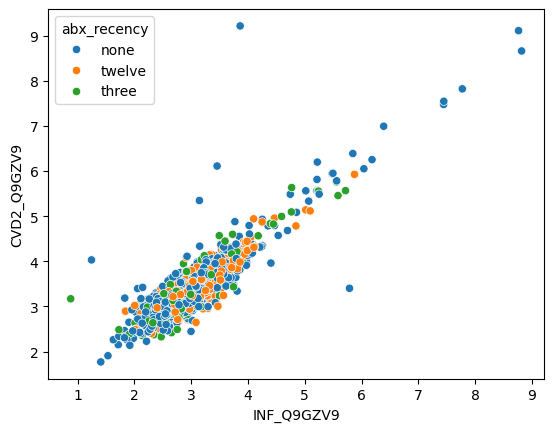

In [20]:
sns.scatterplot(data=fgf_abx_df, x='INF_Q9GZV9', y='CVD2_Q9GZV9', hue='abx_recency')

In [21]:
fgf_abx_df[['INF_Q9GZV9','CVD2_Q9GZV9']].corr(method='spearman')

,INF_Q9GZV9,CVD2_Q9GZV9
INF_Q9GZV9,1.000000,0.840839
CVD2_Q9GZV9,0.840839,1.000000


Above, we can see that most observations are close to the x=y line (spearman corr = 0.84). However, the CVD panel has more extreme values. That is, for someone with a level of FGF of ~1 in the INF panel, this is recorded as 3 in the CVD panel. There are 5 such of these observations in the CVD panel but only 1-2 in the INF panel. Let's also check the missingness.

In [22]:
fgf_abx_df.INF_Q9GZV9.isna().sum()

339

In [23]:
fgf_abx_df.CVD2_Q9GZV9.isna().sum()

342

Nice, it looks like there is also less missingness in the INF panel. Let's stick with the values in that one.

<Axes: xlabel='vitamin_d_flag', ylabel='INF_Q9GZV9'>

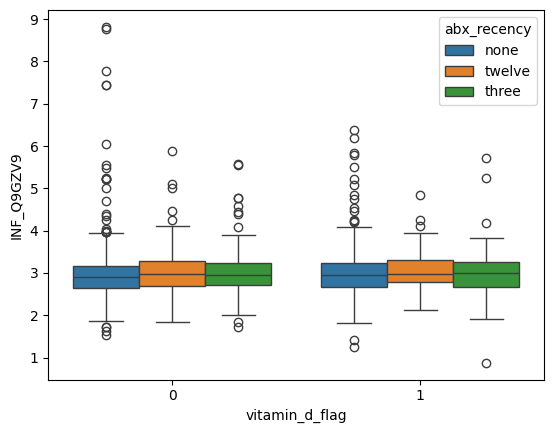

In [24]:
sns.boxplot(data=fgf_abx_df, x='vitamin_d_flag', y='INF_Q9GZV9', hue='abx_recency')

Not seeing too much in the levels of FGF23 with respect to the antibiotic users or vitamin D intake.

<Axes: xlabel='abx_recency', ylabel='CVD2_Q9GZV9'>

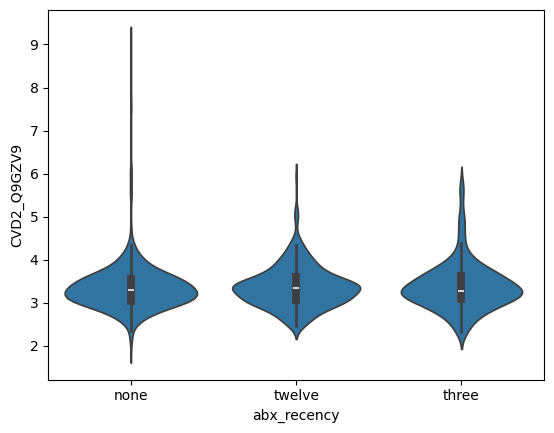

In [25]:
subset = fgf_abx_df[fgf_abx_df['vitamin_d_flag'] == 0]
sns.violinplot(data=subset, x='abx_recency', y='CVD2_Q9GZV9') #INF_Q9GZV9

## Vitamin D use and human genetics
Now looking at polymorphisms in the vitamin D receptor to see if folks in this cohort would be considered "non-responsers" to beneficial effects of vitamin D. 

Good papers to reference are [Dawson-Hughes 2020](https://pmc.ncbi.nlm.nih.gov/articles/PMC7770274/) and [Dawson-Hughes 2026](https://jamanetwork.com/journals/jamanetworkopen/fullarticle/2848109). 

In their work, they mention that there are NR phenotypes in ApaI AA allele and BsmI TT allele. 

In [26]:
snps = adi.get_snapshot('genetics_snp')

In [27]:
vdr_snips_dict = {
    'rs7975232':'ApaI',
    'rs731236':'TaqI',
    'rs2228570':'FokI',
    'rs1544410':'BsmI'}

vdr_snps = ['rs7975232','rs731236','rs2228570','rs1544410']

In [28]:
# Check which VDR snips are present in Arivale
vdr_snps_present = snps.columns[snps.columns.isin(vdr_snips_dict.keys())].tolist()
for present_snp in vdr_snps_present:
    # Access name
    print(vdr_snips_dict[present_snp])

BsmI
FokI
TaqI


**Merge SNPS to vitamin D supplement dataframe**

In [29]:
BsmI_df = snps[['public_client_id','rs1544410']].copy()

In [30]:
abx_fgf_vdr = fgf_abx_df.merge(BsmI_df, how='left', on='public_client_id')

**Merge vitamin D and A1C lab values**

In [31]:
labs_clean = pd.read_csv("data/clincal_chems_abx_users_clean.csv")

In [32]:
vit_d_levels = labs_clean[['public_client_id','VITAMIND_25_OHTOT', 'GLYCOHEMOGLOBINA1C', 'vendor']].copy()

In [33]:
abx_fgf_vdr_vitd = abx_fgf_vdr.merge(vit_d_levels, how='left', on='public_client_id')

In [34]:
abx_fgf_vdr_vitd['rs1544410'].value_counts()

rs1544410
CT    1225
CC     992
TT     362
Name: count, dtype: int64

In [35]:
pd.crosstab(abx_fgf_vdr_vitd['rs1544410'], abx_fgf_vdr_vitd['vitamin_d_flag'])

vitamin_d_flag,0,1
rs1544410,,
CC,648,344
CT,764,461
TT,218,144


In [36]:
pd.crosstab(abx_fgf_vdr_vitd['rs1544410'], abx_fgf_vdr_vitd['abx_recency'])

abx_recency,none,three,twelve
rs1544410,,,
CC,617,141,234
CT,789,170,266
TT,229,52,81


In [37]:
pd.crosstab(abx_fgf_vdr_vitd['vitamin_d_flag'], abx_fgf_vdr_vitd['vendor'])

vendor,LCA,Quest
vitamin_d_flag,,
0,1207,278
1,634,230


<Axes: xlabel='vitamin_d_flag', ylabel='VITAMIND_25_OHTOT'>

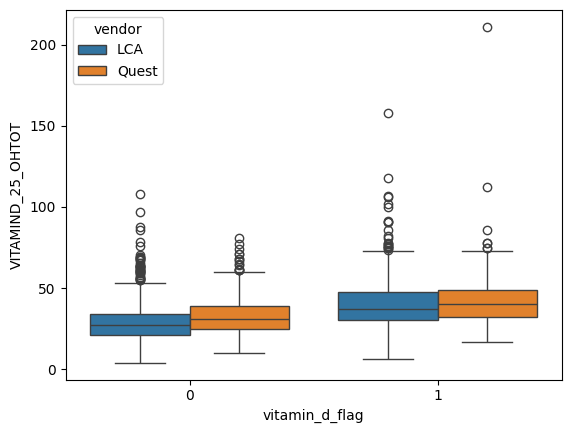

In [38]:
sns.boxplot(data=abx_fgf_vdr_vitd, x='vitamin_d_flag', y='VITAMIND_25_OHTOT', hue='vendor')

In [39]:
# Remove A1Cs in diabetic range
# Remove individuals with T2DM meds
# no_meds = abx_fgf_vdr_vitd[abx_fgf_vdr_vitd['meds_blood_sugar'] == 'No']
# no_t2dm = no_meds[no_meds['GLYCOHEMOGLOBINA1C'] < 6.5]

In [40]:
#sns.boxplot(data=abx_fgf_vdr_vitd, x='rs1544410', y='VITAMIND_25_OHTOT', hue='vitamin_d_flag', order=['CC','CT','TT'])

In [41]:
# Did this visualization because their study was looking at prediabetes
#sns.boxplot(data=no_t2dm, x='rs1544410', y='GLYCOHEMOGLOBINA1C', hue='vitamin_d_flag',  order=['CC','CT','TT'])

In [42]:
# So far, not sure what I see, but that's okie! Let's export this data for analysis in R. 
#abx_fgf_vdr_vitd.to_csv('data/vit_d_snps_fgf_labs_abx_cohort.csv', index=False)

In [43]:
# formula_vitamin_d = ("GLYCOHEMOGLOBINA1C ~ C(abx_recency)*rs1544410 + sex + age + C(meds_blood_sugar) + C(meds_cholesterol)" 
#                         "+ PC1 + PC2 + PC3 + PC4 + PC5 + centered_eGFR + vendor + vitamin_d_flag")
# fitted_vitd_model = ols(formula_vitamin_d, data=no_t2dm).fit()
# fitted_vitd_model.summary()